# P8.15 — Chebyshev-I analógico passa-baixas em forma de cascata

*IIR · protótipo analógico · Chebyshev tipo I · cascata*

> Notebook gerado de `content/p8_15.py`, a mesma fonte da aplicação DSP Filter Lab e do relatório PDF. Para alterar o texto, edite o conteúdo e rode `tools/run_notebook.sh p8_15`.

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Enunciado original

> *Design a lowpass analog Chebyshev-I filter with the following characteristics: A passband ripple of 0.5 dB, passband cutoff frequency of 4 kHz, and stopband attenuation of 45 dB or greater beyond 20 kHz. Determine the system function in a cascade form. Plot the magnitude response, the log-magnitude response in dB, the phase response, and the impulse response of the filter.*

Fonte: DTA §2.2 item 12 e §4 (Resolução P8.15); Ingle & Proakis, pp. 465–466.

## 2. O que está sendo pedido


Projetar um **filtro analógico passa-baixas Chebyshev tipo I** com:

- ondulação de **0.5 dB** na passagem, até $F_p = 4$ kHz;
- atenuação de **45 dB ou mais** a partir de $F_s = 20$ kHz.

O resultado deve ser dado em **forma de cascata** (seções de 2ª ordem). São pedidos quatro gráficos: magnitude, magnitude em dB, **fase** e resposta ao impulso.

## 3. Dados e especificações

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $F_p$ | 4 kHz | ■ Dado do enunciado | borda de passagem |
| $R_p$ | 0.5 dB | ■ Dado do enunciado | ondulação na passagem |
| $F_s$ | 20 kHz | ■ Dado do enunciado | borda de rejeição |
| $A_s$ | 45 dB | ■ Dado do enunciado | atenuação mínima |
| Forma | cascata | ■ Dado do enunciado | produto de seções de 2ª ordem |


Frequências em hertz: a conversão $\Omega = 2\pi F$ vem antes das fórmulas. A transição é larga ($F_s/F_p = 5$), e por isso a ordem vai sair baixa.

## 4. Fundamentação teórica


As fórmulas são as do P8.14 (Chebyshev-I: ondulação constante na passagem, polos sobre uma elipse). A diferença está na forma pedida.

**Cascata.** Cada par conjugado $p, p^*$ forma um biquad real $s^2 - 2\,\mathrm{Re}(p)\,s + |p|^2$. Normalizando cada seção para ganho DC unitário (numerador $= |p|^2$), o ganho global fica com toda a informação de nível. Com $N$ par, esse ganho é $1/\sqrt{1+\epsilon^2}$, porque o DC está num vale da ondulação.

**Vantagem prática.** Em hardware ou software, seções de 2ª ordem em série são muito menos sensíveis a erros de coeficiente que um único polinômio de ordem alta.


#### Aprofundamento: Por que arredondar para cima, mesmo com N_real logo acima de um inteiro?


A fórmula dá $N_{real} = 3.021$, só um pouco acima de 3. Como a ordem precisa ser inteira e **não pode** ficar abaixo do necessário, usa-se 4. A verificação confirma: com $N = 3$, a atenuação em $F_s$ seria 44.58 dB, 0.42 dB abaixo do exigido. Em compensação, $N = 4$ entrega 19.5 dB de folga.

## 5. Equações e variáveis

**(1) Ondulação e ordem** · *DTA §3.2.B*

$$
\epsilon = \sqrt{10^{R_p/10}-1}, \qquad N = \left\lceil \frac{\cosh^{-1} g}{\cosh^{-1}(\Omega_s/\Omega_p)} \right\rceil
$$



**(2) Polos sobre a elipse** · *DTA §3.2.B*

$$
p_k = -a\,\Omega_p\sin\frac{(2k+1)\pi}{2N} + j\,b\,\Omega_p\cos\frac{(2k+1)\pi}{2N}
$$



**(3) Cascata (N par)** · *DTA §4*

$$
H_a(s) = G\prod_{k=1}^{N/2}\frac{|p_k|^2}{s^2 - 2\,\mathrm{Re}(p_k)\,s + |p_k|^2}, \qquad G = \frac{1}{\sqrt{1+\epsilon^2}}
$$

Cada biquad tem ganho DC unitário; $G$ ajusta o nível.

| Símbolo | Significado |
|---|---|
| $G$ | ganho global |

## 6. Resolução passo a passo

### Passo 1 — Converter e calcular ε

Frequências em rad/s; ondulação a partir de $R_p$.

$$
\Omega_p = 2\pi\cdot4000 = 25132.74,\quad \Omega_s = 125663.71\ \text{rad/s}, \qquad \epsilon = \sqrt{10^{0.05}-1} = 0.349311
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\epsilon$ | 0.349311 | ∑ Valor calculado | fator de ondulação |

### Passo 2 — Ordem mínima



$$
g = 509.07, \quad N = \left\lceil \frac{6.9257}{2.2924} \right\rceil = \lceil 3.021 \rceil = 4
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $N$ | 4 | ● Resultado obtido | ordem mínima |

### Passo 3 — Elipse e polos

Semieixos e os 4 polos (dois pares conjugados):

| $k$ | ângulo de $p_k$ | $\lvert p_k\rvert$ | $p_k$ (rad/s) |
|---|---|---|---|
| 0 | 99.8° | $25\,918.65$ | $-4\,407.1 + j25\,541.2$ |
| 1 | 135.2° | $15\,004.31$ | $-10\,639.7 + j10\,579.5$ |
| 2 | 224.8° | $15\,004.31$ | $-10\,639.7 - j10\,579.5$ |
| 3 | 260.2° | $25\,918.65$ | $-4\,407.1 - j25\,541.2$ |

$$
a\Omega_p = 11516.32, \qquad b\Omega_p = 27645.62\ \text{rad/s}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| polos | 4 | ∑ Valor calculado | dois pares conjugados |

### Passo 4 — Formar os biquads

Cada par conjugado vira uma seção com ganho DC unitário:

| Seção | par de polos | coef. de $s$ | termo constante | $\sqrt{\text{const}}/2\pi$ |
|---|---|---|---|---|
| Biquad 1 | $-4\,407.10 \pm j25\,541.22$ | $8814.207$ | $6.7178\times10^{8}$ | 4125.1 Hz |
| Biquad 2 | $-10\,639.69 \pm j10\,579.52$ | $21279.38$ | $2.2513\times10^{8}$ | 2388.0 Hz |

$$
s^2 + 8814.21\,s + 6.7178\times10^{8}, \qquad s^2 + 21279.38\,s + 2.2513\times10^{8}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| seções | 2 | ● Resultado obtido | biquads com numerador = termo constante |

### Passo 5 — Ganho global

Com $N$ par, o DC deve valer $1/\sqrt{1+\epsilon^2}$ (vale da ondulação).

$$
G = \frac{1}{\sqrt{1 + 0.349311^2}} = \frac{1}{1.05925} = 0.94406
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $G$ | 0.94406 | ● Resultado obtido | ganho global |

### Passo 6 — Verificar e confirmar a minimalidade



$$
\text{perda}(F_p) = 0.5000\ \text{dB}, \quad \text{aten.}(F_s) = 64.49\ \text{dB}, \quad N=3:\ 44.58\ \text{dB}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\text{atenuação em } F_s$ | 64.49 dB | ● Resultado obtido | folga de 19.5 dB |
| $N - 1 = 3$ | 44.58 dB | ✓ Critério de validação | < 45 dB: 4 é o mínimo |

## 7. Implementação computacional


1. **Ordem e polos** (`cheb1_order`, `cheb1_poles`), conferidos com o SciPy nos testes.
2. **Cascata** (`forms.cascade`): agrupa os pares conjugados em biquads com ganho DC unitário e calcula $G = k/\prod \text{num}_k$. Um teste confirma que o produto das seções reproduz a resposta do filtro.
3. **Análise**: magnitude e fase a partir dos polos; $h(t)$ conferida com a inversa de Laplace por resíduos.


| Função | O que faz |
|---|---|
| `dsp_av2.iir.prototypes.cheb1_order` | Passos 1–2 |
| `dsp_av2.iir.prototypes.cheb1_poles` | Passo 3 |
| `dsp_av2.iir.forms.cascade` | Passos 4–5: biquads e ganho |
| `dsp_av2.validation.validate_analog_lowpass` | Passo 6 |

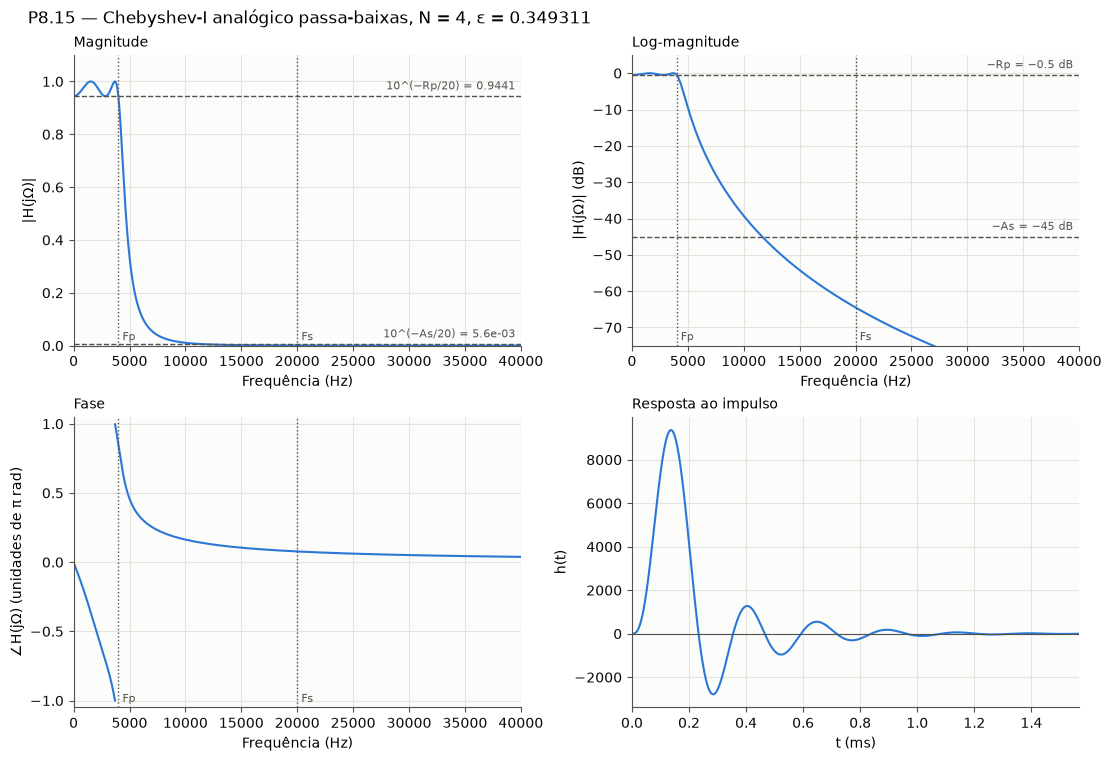

In [2]:
from content import p8_15 as content_mod
objs = content_mod.objects()
import matplotlib.pyplot as plt
from exercises import p8_15
fig = p8_15.plot(objs['proto'])
plt.show()

## 8. Gráficos e interpretação

### Polos no plano $s$


Dois pares conjugados sobre a elipse do Chebyshev. O par mais alto (mais perto do eixo $j\Omega$) responde pela oscilação perto de $F_p$, e o par mais baixo, pela parte de baixa frequência.


### Magnitude


$N + 1 = 5$ extremos em $[0, F_p]$, começando no vale $0.9441$ em DC (N par). Depois de $F_p$, a queda é monotônica.


### Magnitude em dB


Ondulação de 0.5 dB até 4 kHz e 64.49 dB em 20 kHz, 19.5 dB além do exigido, por causa do arredondamento $N_{real} = 3.02 \to 4$.


### Fase


A fase total vai de 0 a $-N\pi/2 = -4\pi/2$. O traço principal salta de $-\pi$ para $+\pi$ perto de $F_p$, onde a fase varia mais rápido, e depois tende ao valor final, equivalente a $-4\pi/2$ módulo $2\pi$.


### Resposta ao impulso


Oscilação amortecida dominada pelo par de polos de menor amortecimento, com frequência próxima de $F_p$ e duração da ordem de 1 ms.

## 9. Verificação das especificações


Perda máxima em $[0, \Omega_p]$ ≤ $R_p$, atenuação mínima em $[\Omega_s, 100\,\Omega_s]$ ≥ $A_s$, e minimalidade ($N - 1$ não atende).

In [3]:
rep = objs.get('final_report') or objs.get('report')
print(rep)

Validação P8.15
  [OK  ] Perda máx. na passagem [dB]: 0.5000 <= 0.5000  (folga +0.0000)
  [OK  ] Atenuação mín. na rejeição [dB]: 64.4909 >= 45.0000  (folga +19.4909)
  [OK  ] Atenuação em Ωs com N−1 = 3 [dB] (deve falhar): 44.5792 <= 45.0000  (folga +0.4208)
  Resultado: ATENDE à especificação


## 10. Conclusão técnica


- $\epsilon = 0.349311$ e **$N = 4$** ($\lceil 3.021 \rceil$).
- Cascata: $H_a(s) = 0.94406 \cdot \frac{6.7178\times10^{8}}{s^2 + 8814.21s + 6.7178\times10^{8}} \cdot \frac{2.2513\times10^{8}}{s^2 + 21279.38s + 2.2513\times10^{8}}$, idêntica ao DTA.
- Perda de 0.5 dB em 4 kHz e 64.49 dB em 20 kHz. Com $N = 3$ faltariam 0.42 dB.